# Apache Airflow Foundations

**Apache Airflow** is the most widely used open-source orchestrator. A pipeline is a **DAG** (directed acyclic graph) of **tasks** written in Python; the **scheduler** decides when each task runs, **executors** run them, and the web UI and REST API show their state. This lesson runs a real **Airflow 3** instance in Docker and controls it from the notebook through the REST API.

**After this lesson you can:**

1. Explain DAGs, tasks, operators, the scheduler, executors and XComs.
2. Write a DAG with the TaskFlow API (`@dag`, `@task`).
3. Deploy, trigger and monitor DAG runs through the REST API.
4. Understand schedules, logical dates, catchup and retries.

**Services:** `docker compose -f docker/compose.yml --profile orchestration up -d` starts Airflow 3 in standalone mode at http://localhost:8080 (no login, local learning only). Open the UI in a browser to watch the runs of this notebook live.

In [1]:
import sys
import textwrap
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
datasets.ensure_service("orchestration", "airflow", timeout=900)      # Airflow 3 standalone in Docker (first start: a few minutes)
API = "http://localhost:8080/api/v2"
DAGS = datasets.ROOT / "data" / "cache" / "airflow" / "dags"          # mounted into the container as /opt/airflow/dags
OUT = datasets.ROOT / "data" / "cache" / "airflow" / "output"         # mounted as /opt/airflow/output
DATA_IN_CONTAINER = "/opt/airflow/course_data"                        # the course data cache, read-only

def deploy(dag_id: str, source: str, timeout: int = 120) -> None:
    """Write a DAG file and wait until Airflow has parsed it; then unpause it."""
    (DAGS / f"{dag_id}.py").write_text(textwrap.dedent(source).strip() + "\n", encoding="utf-8")
    deadline = time.time() + timeout
    while time.time() < deadline:
        r = requests.get(f"{API}/dags/{dag_id}", timeout=10)
        if r.status_code == 200:
            requests.patch(f"{API}/dags/{dag_id}", json={"is_paused": False}, timeout=10)
            return
        time.sleep(3)
    errors = requests.get(f"{API}/importErrors", timeout=10).json()
    raise RuntimeError(f"DAG {dag_id} was not parsed in time; import errors: {errors}")

def trigger(dag_id: str, conf: dict | None = None) -> str:
    r = requests.post(f"{API}/dags/{dag_id}/dagRuns", json={"logical_date": None, "conf": conf or {}}, timeout=10)
    r.raise_for_status()
    return r.json()["dag_run_id"]

def wait(dag_id: str, run_id: str, timeout: int = 300) -> str:
    deadline = time.time() + timeout
    while time.time() < deadline:
        state = requests.get(f"{API}/dags/{dag_id}/dagRuns/{run_id}", timeout=10).json()["state"]
        if state in ("success", "failed"):
            return state
        time.sleep(3)
    return "timeout"

def tasks(dag_id: str, run_id: str) -> pd.DataFrame:
    ti = requests.get(f"{API}/dags/{dag_id}/dagRuns/{run_id}/taskInstances", params={"limit": 100}, timeout=10).json()["task_instances"]
    df = pd.DataFrame(ti)[["task_id", "map_index", "state", "try_number", "start_date", "end_date", "duration"]]
    for c in ["start_date", "end_date"]:
        df[c] = pd.to_datetime(df[c])
    return df.sort_values("start_date").reset_index(drop=True)

def xcom(dag_id: str, run_id: str, task_id: str, map_index: int = -1):
    r = requests.get(f"{API}/dags/{dag_id}/dagRuns/{run_id}/taskInstances/{task_id}/xcomEntries/return_value",
                     params={"map_index": map_index, "deserialize": True}, timeout=10)
    return r.json().get("value")

def gantt(df: pd.DataFrame, title: str) -> None:
    t0 = df["start_date"].min()
    fig, ax = plt.subplots(figsize=(9, 0.45 * len(df) + 1))
    colors = {"success": "#59A14F", "failed": "#E15759", "skipped": "#BAB0AC", "upstream_failed": "#F28E2B"}
    labels = [f"{t}[{m}]" if m >= 0 else t for t, m in zip(df["task_id"], df["map_index"])]
    for i, r in df.iterrows():
        if pd.notna(r["start_date"]):
            ax.barh(i, (r["end_date"] - r["start_date"]).total_seconds(), left=(r["start_date"] - t0).total_seconds(),
                    color=colors.get(r["state"], "#4E79A7"))
    ax.set(yticks=range(len(df)), yticklabels=labels, xlabel="Seconds since the first task started", title=title)
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()

health = requests.get(f"{API}/monitor/health", timeout=10).json()
print("Airflow components:", {k: v["status"] for k, v in health.items()})
print("Airflow version:", requests.get(f"{API}/version", timeout=10).json()["version"])

Airflow components: {'metadatabase': 'healthy', 'scheduler': 'healthy', 'triggerer': 'healthy', 'dag_processor': 'healthy'}
Airflow version: 3.1.0


## 1. Core Concepts

| Concept | Meaning |
| :--- | :--- |
| **DAG** | a pipeline: tasks and their dependencies, plus a schedule |
| **task** | one unit of work (a Python function, a SQL query, a container) |
| **operator** | a template for a task (`PythonOperator`, `BashOperator`, `SQLExecuteQueryOperator`, ...) |
| **TaskFlow API** | `@task`-decorated functions; dependencies and data passing from function calls |
| **XCom** | small values passed between tasks (stored in the metadata database; not for large data) |
| **scheduler** | creates DAG runs according to the schedule and queues tasks whose upstream tasks succeeded |
| **executor** | runs the tasks: local processes, Celery workers, Kubernetes pods |
| **DAG run** | one execution of a DAG for one data interval |

## 2. A First DAG: Daily Taxi Summary

The DAG has three tasks: **extract** (count trips per day from the Parquet file), **transform** (find the busiest day), **load** (write a summary file). Large data stays in files; only small results travel through XCom.

In [2]:
deploy("taxi_daily_summary", f"""
from datetime import datetime, timedelta
from airflow.sdk import dag, task

DATA = "{DATA_IN_CONTAINER}"

@dag(
    schedule="@daily",
    start_date=datetime(2024, 1, 1),
    catchup=False,
    default_args={{"retries": 2, "retry_delay": timedelta(seconds=5)}},
    tags=["course", "m11"],
    doc_md="Counts NYC taxi trips per day and writes a summary.",
)
def taxi_daily_summary():

    @task
    def extract(month: str = "2024-01") -> str:
        import duckdb
        out = f"/opt/airflow/output/daily_counts_{{month}}.parquet"
        duckdb.execute(f\"\"\"
            COPY (SELECT CAST(tpep_pickup_datetime AS DATE) AS day, count(*) AS trips, sum(total_amount) AS revenue
                  FROM read_parquet('{{DATA}}/yellow_tripdata_{{month}}.parquet')
                  WHERE tpep_pickup_datetime >= DATE '{{month}}-01'
                    AND tpep_pickup_datetime < DATE '{{month}}-01' + INTERVAL 1 MONTH AND fare_amount BETWEEN 3 AND 500
                  GROUP BY 1 ORDER BY 1) TO '{{out}}' (FORMAT parquet)\"\"\")
        return out                                     # only the path goes through XCom

    @task
    def transform(path: str) -> dict:
        import duckdb
        day, trips = duckdb.execute(f"SELECT day, trips FROM '{{path}}' ORDER BY trips DESC LIMIT 1").fetchone()
        days, total = duckdb.execute(f"SELECT count(*), sum(trips) FROM '{{path}}'").fetchone()
        return {{"busiest_day": str(day), "busiest_trips": int(trips), "days": int(days), "total_trips": int(total)}}

    @task
    def load(summary: dict) -> str:
        import json
        path = "/opt/airflow/output/summary.json"
        with open(path, "w") as f:
            json.dump(summary, f)
        return path

    load(transform(extract()))

taxi_daily_summary()
""")
dag = requests.get(f"{API}/dags/taxi_daily_summary/details", timeout=10).json()
print({k: dag.get(k) for k in ["dag_id", "timetable_summary", "is_paused", "max_active_runs", "fileloc"] if k in dag})

{'dag_id': 'taxi_daily_summary', 'timetable_summary': '0 0 * * *', 'is_paused': False, 'max_active_runs': 16, 'fileloc': '/opt/airflow/dags/taxi_daily_summary.py'}


## 3. Trigger a Run and Watch It

In [3]:
run_id = trigger("taxi_daily_summary")
state = wait("taxi_daily_summary", run_id)
ti = tasks("taxi_daily_summary", run_id)
print("run", run_id, "->", state)
print(ti[["task_id", "state", "try_number", "duration"]].to_string(index=False))
print("\nresult of 'transform' (XCom):", xcom("taxi_daily_summary", run_id, "transform"))

run manual__2026-11-16T20:22:32.306786+00:00_yXYSJEDr -> success
  task_id   state  try_number  duration
  extract success           2  1.315325
transform success           1  2.205823
     load success           1  0.785432

result of 'transform' (XCom): {'days': 31, 'busiest_day': '2024-01-18', 'total_trips': 2924610, 'busiest_trips': 109007}


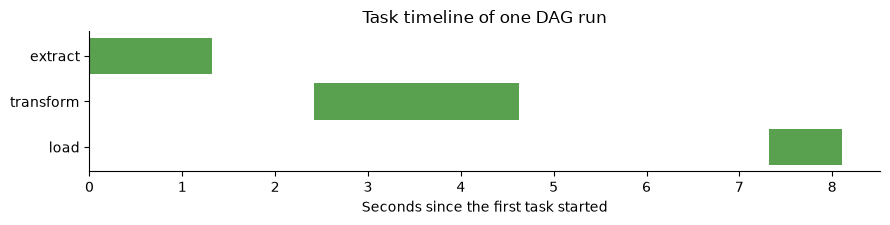

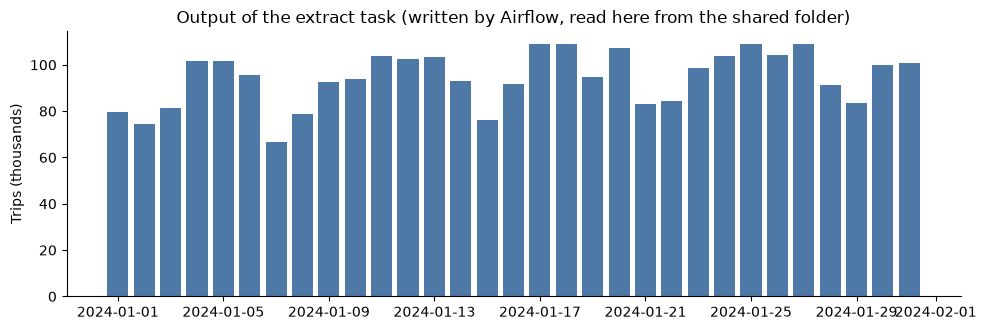

In [4]:
gantt(ti, "Task timeline of one DAG run")
daily = pd.read_parquet(OUT / "daily_counts_2024-01.parquet")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(pd.to_datetime(daily["day"]), daily["trips"] / 1000, color="#4E79A7")
ax.set(title="Output of the extract task (written by Airflow, read here from the shared folder)", ylabel="Trips (thousands)")
plt.tight_layout()
plt.show()

## 4. Schedules, Logical Dates and Catchup

- `schedule` accepts presets (`@daily`, `@hourly`), cron expressions (`"0 6 * * 1-5"`: 06:00 on weekdays), timedeltas, timetables, or **assets** (Lesson 07).
- Each scheduled run covers a **data interval**. A daily run for 2024-01-15 starts **after** that day ends, because the day's data is complete only then.
- With `catchup=True`, Airflow creates runs for every interval since `start_date` that has not run yet; with `catchup=False` (default in Airflow 3), only the latest.
- `retries` and `retry_delay` make tasks tolerant of temporary failures (network, locks). Retries require **idempotent** tasks (Lesson 09).

The task log is available through the API (and in the UI):

In [5]:
log = requests.get(f"{API}/dags/taxi_daily_summary/dagRuns/{run_id}/taskInstances/transform/logs/1",
                   params={"full_content": True}, headers={"Accept": "application/json"}, timeout=10).json()
events = [e.get("event") for e in log["content"] if isinstance(e, dict) and e.get("event")]
print("\n".join(str(e)[:120] for e in events[-6:]))

::group::Log message source details
::endgroup::
DAG bundles loaded: dags-folder
Filling up the DagBag from /opt/airflow/dags/taxi_daily_summary.py
Done. Returned value was: {'busiest_day': '2024-01-18', 'busiest_trips': 109007, 'days': 31, 'total_trips': 2924610}
Pushing xcom


## 5. Good DAG Habits

| Habit | Why |
| :--- | :--- |
| keep heavy work out of the DAG file's top level | the file is parsed every few seconds |
| pass paths or keys through XCom, not data | XCom lives in the metadata database |
| make tasks idempotent | retries and re-runs must not duplicate data |
| one task = one logical step | clear retries, clear logs |
| use connections and variables for secrets | never write credentials in DAG code |
| test DAGs in CI (`dag.test()`, import checks) | catch errors before deployment |

*Insight: Airflow runs Python tasks in dependency order on a schedule, with retries, logs and history. Keep DAG files light, tasks idempotent, and data out of XCom; control and observe everything through the UI or the REST API.*

## Real-World Use Case or Analogy

Airflow is like a **railway timetable with a control room**: each train (task) leaves only when the connecting trains have arrived (dependencies), at the scheduled time (schedule), and the control room (UI) shows delays, cancellations and the full history of every journey.

Airflow started at Airbnb in 2014 and became an Apache top-level project; managed versions exist on all major clouds (Amazon MWAA, Google Cloud Composer, Astronomer).